<a href="https://colab.research.google.com/github/riasharma0902/BMEN-600-Project/blob/main/Untitled9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving BraTS-PEDs_metadata (3).tsv to BraTS-PEDs_metadata (3) (1).tsv


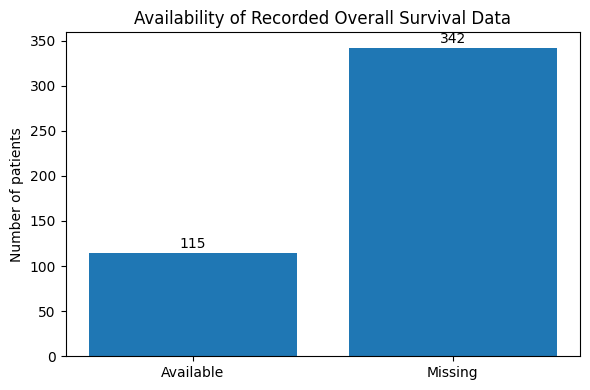

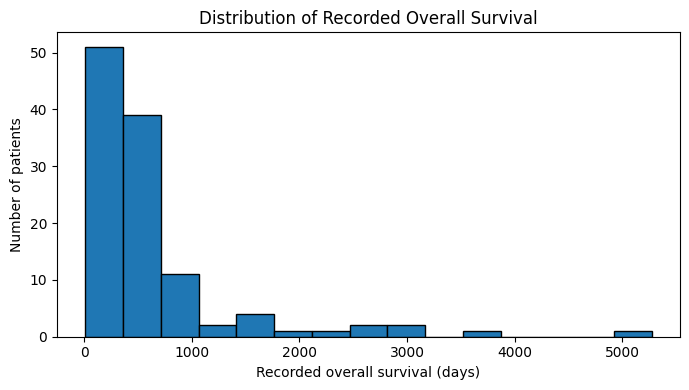

count     115.000000
mean      641.234783
std       788.584389
min        10.000000
25%       241.000000
50%       397.000000
75%       626.500000
max      5274.000000
Name: Overall survival (days), dtype: float64


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload the challenge metadata TSV
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename, sep="\t")

# Convert recorded survival values to numbers
survival = pd.to_numeric(
    df["Overall survival (days)"],
    errors="coerce"
)

# Figure 1: Missing survival values
counts = [
    survival.notna().sum(),
    survival.isna().sum()
]

plt.figure(figsize=(6, 4))
plt.bar(
    ["Available", "Missing"],
    counts
)
plt.ylabel("Number of patients")
plt.title("Availability of Recorded Overall Survival Data")

for i, count in enumerate(counts):
    plt.text(i, count + 5, str(count), ha="center")

plt.tight_layout()
plt.savefig("survival_availability.png", dpi=300)
plt.show()

# Figure 2: Distribution of recorded survival
plt.figure(figsize=(7, 4))
plt.hist(survival.dropna(), bins=15, edgecolor="black")
plt.xlabel("Recorded overall survival (days)")
plt.ylabel("Number of patients")
plt.title("Distribution of Recorded Overall Survival")

plt.tight_layout()
plt.savefig("survival_distribution.png", dpi=300)
plt.show()

# Descriptive statistics
print(survival.describe())


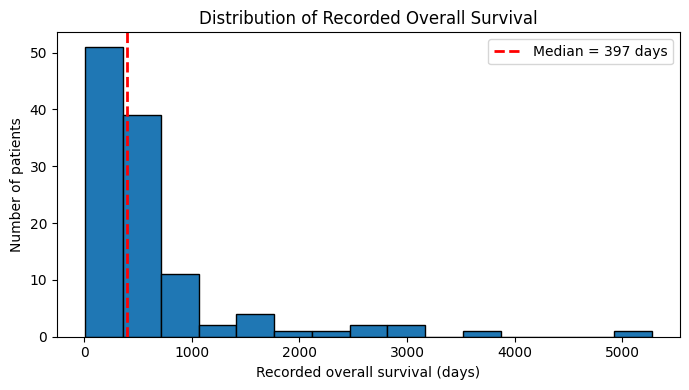

In [ ]:

plt.figure(figsize=(7, 4))

# Plot the distribution
plt.hist(survival.dropna(), bins=15, edgecolor="black")

# Calculate and display the median
median_survival = survival.median()

plt.axvline(
    median_survival,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_survival:.0f} days"
)

plt.xlabel("Recorded overall survival (days)")
plt.ylabel("Number of patients")
plt.title("Distribution of Recorded Overall Survival")

# Show the median in the legend
plt.legend()

plt.tight_layout()
plt.savefig("survival_distribution.png", dpi=300)
plt.show()
